<a href="https://colab.research.google.com/github/shabi-2-2/ML_zero_to_hero/blob/main/MicroGrad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
import random
%matplotlib inline

In [ ]:
def f(x):
  return 3*x**2 - 4*x + 5

In [ ]:
f(3.0)

20.0

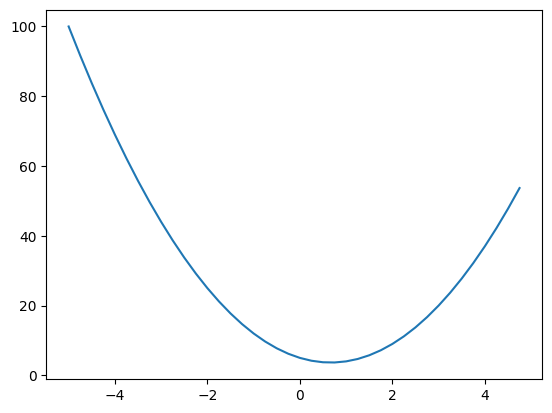

In [ ]:
xs=np.arange(-5,5,0.25)
ys=f(xs)
plt.plot(xs,ys)


In [ ]:
# what is the derivative of f(x)
h=0.00001
x=2/3
(f(x+h)-f(x))/h

3.0000002482211127e-05

In [ ]:
# more complex case
h=0.0000001
a = 2.0
b = -3.0
c = 10.0
d = a*b+c
print(d)

4.0


In [ ]:
h=0.000000001
a = 2.0
b = -3.0
c = 10.0
d1 = a*b+c
c+=h
d2 = a*b+c

print("d1",d1)
print("d2",d2)

print("slope",(d2-d1)/h)

d1 4.0
d2 4.000000001
slope 1.000000082740371


In [ ]:
class Value:
  def __init__(self,data,_children=(), _op='',label=''):
    self.data=data
    self.grad=0.0
    self._prev=set(_children)
    self._op=_op
    self.label=label
    self._backward=lambda:None
  def __repr__(self):
    return f"Value(data={self.data})"
  def __add__(self,other):
    other=other if isinstance(other,Value) else Value(other)
    out= Value(self.data+other.data,(self,other),'+')

    def _backward():
      self.grad+=1.0*out.grad
      other.grad+=1.0*out.grad

    out._backward=_backward
    return out
  def __mul__(self,other):
    other=other if isinstance(other,Value) else Value(other)
    out= Value(self.data*other.data,(self,other),'*')

    def _backward():
      self.grad+=(other.data)*out.grad
      other.grad+=self.data*out.grad

    out._backward=_backward
    return out

  def __pow__(self,other):
    assert isinstance(other, (int,float));"only supporting float and int for now"
    out=Value(self.data**other,(self,), f'**{other}')

    def _backward():
      self.grad+=other*(self.data**(other-1)) * out.grad
    out._backward=_backward

    return out


  def __rmul__(self,other): #other*self
    return self*other

  def __truediv__(self,other):#self/other
      return self*(other)**-1

  def __neg__(self):
    return self*-1;

  def __sub__(self,other):
    return self + (- other);

  def __radd__(self,other):
    return self+other

  def tanh(self):
    x=self.data
    t=(math.exp(2*x)-1)/(math.exp(2*x)+1)
    out=Value(t,(self,),'tanh')

    def _backward():
      self.grad+=(1-(t**2))*out.grad
    out._backward=_backward
    return out

  def exp(self):
    x=self.data
    out=Value(math.exp(x),(self,),'exp')

    def _backward():
      self.grad=out.data*out.grad
    out._backward=_backward
    return out

  def backward(self):
    topo=[]
    visited=set()
    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)
    topo
    self.grad=1.0
    for node in reversed(topo):
      node._backward()


In [ ]:
a=Value(2.0)
b=Value(4.0)
a-b

Value(data=-2.0)

In [ ]:
  a=Value(2.0,label='a')
  b=Value(-3.0,label='b')
  c=Value(10.0,label='c')
  e=a*b;e.label='e'
  d=e+c;d.label='d'
  f=Value(-2.0,label='f')
  L=d*f;L.label='L'

In [ ]:
from graphviz import Digraph

def trace(root):
  # build a set of all nodes and edges in a graph
  nodes,edges=set(),set()
  def build(v):
    if v not in nodes:
      nodes.add(v)
      for child in v._prev:
        edges.add((child,v))
        build(child)
  build(root)
  return nodes,edges

def draw_dot(root):
  dot =Digraph(format='svg', graph_attr={'rankdir':'LR'})# LR->left to right

  nodes,edges= trace(root)
  for n in nodes:
    uid = str(id(n))
    # for any value in the graph, create a rectangular ('record') node for it
    dot.node(name = uid, label="{%s | data %.4f | grad %.4f}"%(n.label,n.data,n.grad),shape='record')
    if n._op:
    # if this value is a result of some operations, create an op node for it
      dot.node(name=uid + n._op,label=n._op)
    # and connect this node to it
      dot.edge(uid+n._op,uid)
  for n1,n2 in edges:
  # connect n1 to the op node of n2
    dot.edge(str(id(n1)),str(id(n2))+ n2._op)
  return dot


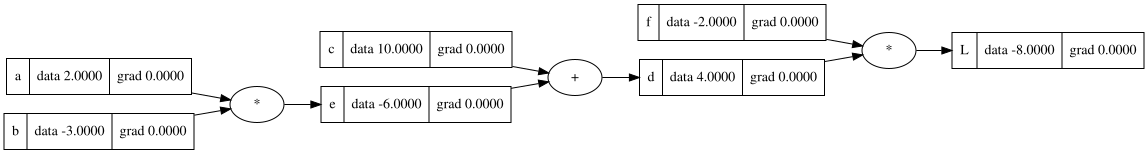

In [ ]:
draw_dot(L)

In [ ]:
a.data+=0.01*a.grad
b.data+=0.01*b.grad
c.data+=0.01*c.grad
f.data+=0.01*f.grad

e=a*b
d=e+c
L=d*f
print(L.data)


-8.0


In [ ]:
def lol():
  h=0.0000001

  a=Value(2.0,label='a')
  b=Value(-3.0,label='b')
  c=Value(10.0,label='c')
  e=a*b;e.label='e'
  d=e+c;d.label='d'
  f=Value(-2.0,label='f')
  L=d*f;L.label='L'
  L1=L.data

  a=Value(2.0,label='a')
  b=Value(-3.0,label='b')
  b.data
  c=Value(10.0,label='c')
  e=a*b;e.label='e'
  d=e+c;d.label='d'
  f=Value(-2.0,label='f')
  L=d*f;L.label='L'
  L2=L.data


  print((L2-L1)/h)
lol()

0.0


In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()

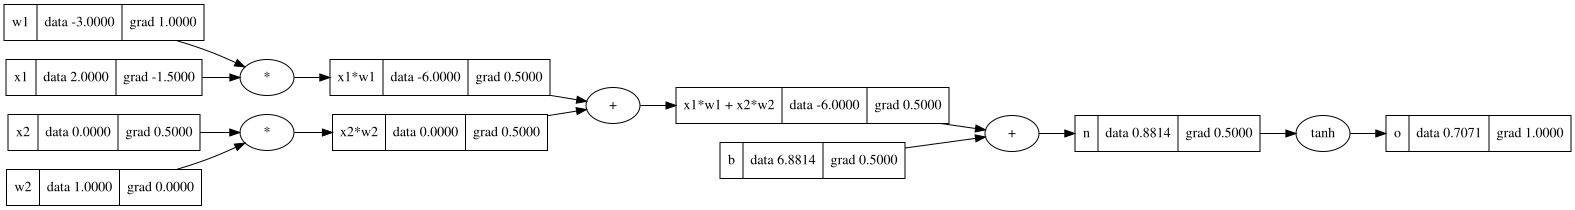

In [ ]:
draw_dot(o)

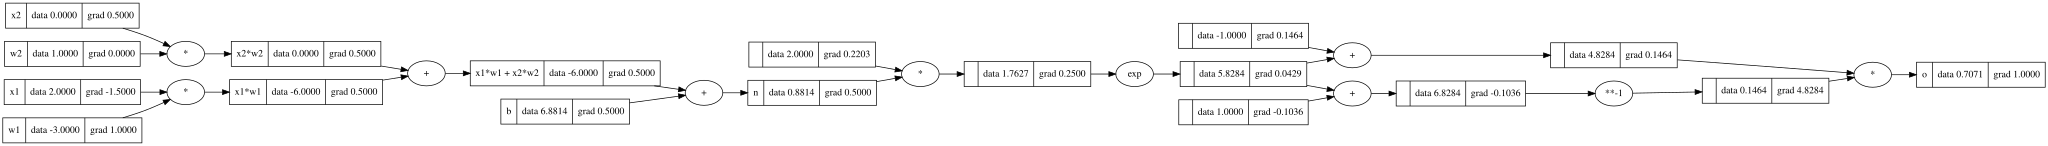

In [ ]:
# inputs x1,x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
# weights w1,w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
# bias of the neuron
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1.label = 'x1*w1'
x2w2 = x2*w2; x2w2.label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
# ---------- doing forward pass
e = (2*n).exp()
o = (e - 1)/(e + 1)
# ----------
o.label = 'o'
o.backward()
draw_dot(o)

In [ ]:
import torch

In [ ]:
x1 = torch.Tensor([2.0]).double()                ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()                ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()               ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()                ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())


0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
class Neuron:

  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:

  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:

  def __init__(self, nin, nouts):
    sz = [nin] + nouts
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [ ]:
x = [2.0 , 3.0, -1.0]
n=MLP(3,[4,4,1])
n(x)


Value(data=-0.4850068210261846)

In [ ]:
xs=[
    [2.0,3.0,-1.0],
    [3.0,-1.0,0.5],
    [0.5,1.0,1.0],
    [1.0,1.0,-1.0]
]
ys =[1.0,-1.0,-1.0,1.0] #desired targets

In [ ]:
for k in range(20):
  # forward pass
  ypred=[n(x) for x in xs]
  loss = sum((yout-ygt)**2 for ygt,yout in zip(ys,ypred))

  # backward pass
  for p in n.parameters():
    p.grad=0.0
  loss.backward()

  # update
  for p in n.parameters():
    p.data+= -0.05*p.grad

  print(k,loss.data)

0 5.7968330278754445
1 3.7947731917629084
2 3.3157677827753407
3 3.002673319002073
4 2.7412981564881176
5 2.4798404111032215
6 2.1702303215870553
7 1.7806910069852004
8 1.3292809842218032
9 0.9133230227143874
10 0.6220152492580902
11 0.44587659315465095
12 0.33877442835684207
13 0.2694963120692281
14 0.2218266309729413
15 0.18734636929247542
16 0.16141220141519752
17 0.14129266979688965
18 0.1252887081237775
19 0.11229333390013467


In [ ]:
ypred

[Value(data=0.7995240259257071),
 Value(data=-0.813429338691995),
 Value(data=-0.8512731748255602),
 Value(data=0.8768154330619155)]

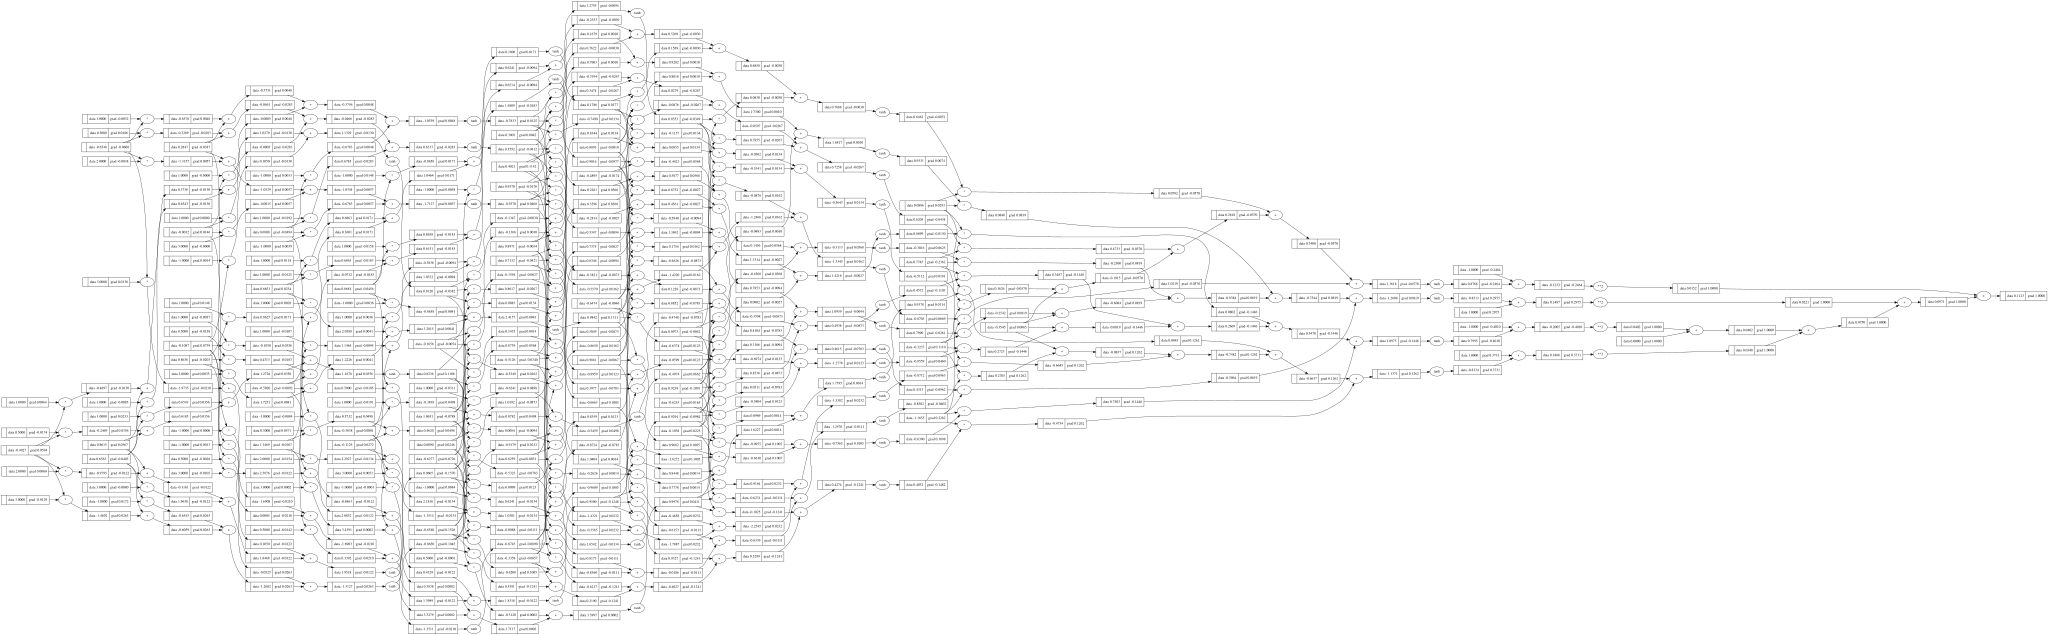

In [ ]:
draw_dot(loss)